# 03 – Exploratory Data Analysis (EDA)

## 1. Introduction

### Project: Rate My Recipe – Food.com Recipe Ranking System

### Objective

The objective of this notebook is to perform Exploratory Data Analysis (EDA) on the Food.com recipe and user interaction datasets.

EDA helps us understand the structure, distributions, patterns, and relationships within the data before developing the final recipe-ranking application.

### Key Activities

1. Explore recipe characteristics such as cooking time, ingredients, preparation steps, and nutrition.
2. Analyze recipe ratings and popularity.
3. Investigate relationships between recipe characteristics and user ratings.
4. Create meaningful visualizations to communicate important patterns.
5. Document key findings that support the recipe-ranking system.

### Data Sources

- **Processed recipe dataset:** `data/processed/processed_recipes.csv`
- **Raw user interaction dataset:** `data/raw/RAW_interactions.csv`

### Approach

This notebook uses the reusable preprocessing and ranking logic developed in the `src/` directory. Previously completed cleaning and preprocessing operations will not be repeated unnecessarily.

In [1]:
# Import required libraries

import os
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visualizations

sns.set_theme(style="whitegrid")

# Display settings

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

print("Required libraries imported successfully.")

Required libraries imported successfully.


In [2]:
# Get the current notebook working directory

current_directory = os.getcwd()

# Identify the project root directory

project_root = os.path.dirname(current_directory)

# Add project root to Python path

if project_root not in sys.path:
    sys.path.append(project_root)

print("CURRENT WORKING DIRECTORY")
print("-" * 60)
print(current_directory)

print("\nPROJECT ROOT")
print("-" * 60)
print(project_root)

print("\nProject root added to Python path:",
      project_root in sys.path)

CURRENT WORKING DIRECTORY
------------------------------------------------------------
/Users/mrmac/Documents/Venudatta_Python_project_My-recipe/notebooks

PROJECT ROOT
------------------------------------------------------------
/Users/mrmac/Documents/Venudatta_Python_project_My-recipe

Project root added to Python path: True


In [3]:
# Define dataset paths

processed_recipes_path = os.path.join(
    project_root,
    "data",
    "processed",
    "processed_recipes.csv"
)

raw_interactions_path = os.path.join(
    project_root,
    "data",
    "raw",
    "RAW_interactions.csv"
)


# Load processed recipe dataset

recipes = pd.read_csv(processed_recipes_path)


# Load raw interaction dataset

interactions = pd.read_csv(raw_interactions_path)


print("DATASETS LOADED SUCCESSFULLY")
print("-" * 60)

print("Recipes dataset shape:", recipes.shape)
print("Interactions dataset shape:", interactions.shape)

print("\nRecipe dataset columns:")
print(recipes.columns.tolist())

print("\nInteraction dataset columns:")
print(interactions.columns.tolist())

DATASETS LOADED SUCCESSFULLY
------------------------------------------------------------
Recipes dataset shape: (231636, 21)
Interactions dataset shape: (1132367, 5)

Recipe dataset columns:
['name', 'id', 'minutes', 'contributor_id', 'submitted', 'tags', 'n_steps', 'steps', 'description', 'ingredients', 'n_ingredients', 'calories', 'total_fat_pdv', 'sugar_pdv', 'sodium_pdv', 'protein_pdv', 'saturated_fat_pdv', 'carbohydrates_pdv', 'ingredient_count', 'tag_count', 'step_count']

Interaction dataset columns:
['user_id', 'recipe_id', 'date', 'rating', 'review']


## 2. Recipe Dataset Overview

The processed recipe dataset contains 231,636 recipes and 21 columns.

These columns describe recipe information, preparation characteristics, nutritional values, and engineered features.

The dataset variables can be grouped into the following categories:

1. **Recipe identification:** Recipe name, recipe ID, and contributor ID.
2. **Recipe preparation:** Cooking time, number of steps, and ingredients.
3. **Recipe metadata:** Submission date, tags, and description.
4. **Nutrition information:** Calories, fat, sugar, sodium, protein, saturated fat, and carbohydrates.
5. **Engineered features:** Ingredient count, tag count, and step count.

This section examines the dataset structure and summarizes its numerical variables before proceeding to detailed analysis.

In [4]:
# Display the first five recipes

print("FIRST FIVE RECIPES")
print("-" * 60)

display(recipes.head())

FIRST FIVE RECIPES
------------------------------------------------------------


,name,id,minutes,contributor_id,submitted,tags,n_steps,steps,description,ingredients,n_ingredients,calories,total_fat_pdv,sugar_pdv,sodium_pdv,protein_pdv,saturated_fat_pdv,carbohydrates_pdv,ingredient_count,tag_count,step_count
0,arriba baked winter squash mexican style,137739,55.0,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",11,"['make a choice and proceed with recipe', 'depending on size of squash , cut into half or fourth...",autumn is my favorite time of year to cook! this recipe \r\ncan be prepared either spicy or swee...,"['winter squash', 'mexican seasoning', 'mixed spice', 'honey', 'butter', 'olive oil', 'salt']",7,51.5,0.0,13.0,0.0,2.0,0.0,4.0,7,20,11
1,a bit different breakfast pizza,31490,30.0,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'o...",9,"['preheat oven to 425 degrees f', 'press dough into the bottom and sides of a 12 inch pizza pan'...",this recipe calls for the crust to be prebaked a bit before adding ingredients. feel free to cha...,"['prepared pizza crust', 'sausage patty', 'eggs', 'milk', 'salt and pepper', 'cheese']",6,173.4,18.0,0.0,17.0,22.0,35.0,1.0,6,20,9
2,all in the kitchen chili,112140,130.0,196586,2005-02-25,"['time-to-make', 'course', 'preparation', 'main-dish', 'chili', 'crock-pot-slow-cooker', 'dietar...",6,"['brown ground beef in large pot', 'add chopped onions to ground beef when almost brown and saut...",this modified version of 'mom's' chili was a hit at our 2004 christmas party. we made an extra l...,"['ground beef', 'yellow onions', 'diced tomatoes', 'tomato paste', 'tomato soup', 'rotel tomatoe...",13,269.8,22.0,32.0,48.0,39.0,27.0,5.0,13,9,6
3,alouette potatoes,59389,45.0,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course', 'main-ingredient', 'preparation', 'occasion', '...",11,"['place potatoes in a large pot of lightly salted water and bring to a gentle boil', 'cook until...","this is a super easy, great tasting, make ahead side dish that looks like you spent a lot more t...","['spreadable cheese with garlic and herbs', 'new potatoes', 'shallots', 'parsley', 'tarragon', '...",11,368.1,17.0,10.0,2.0,14.0,8.0,20.0,11,30,11
4,amish tomato ketchup for canning,44061,190.0,41706,2002-10-25,"['weeknight', 'time-to-make', 'course', 'main-ingredient', 'cuisine', 'preparation', 'occasion',...",5,"['mix all ingredients& boil for 2 1 / 2 hours , or until thick', 'pour into jars', ""i use'old' g...",my dh's amish mother raised him on this recipe. he much prefers it over store-bought ketchup. it...,"['tomato juice', 'apple cider vinegar', 'sugar', 'salt', 'pepper', 'clove oil', 'cinnamon oil', ...",8,352.9,1.0,337.0,23.0,3.0,0.0,28.0,8,21,5


In [5]:
# Generate descriptive statistics for numerical columns

print("NUMERICAL SUMMARY STATISTICS")
print("-" * 60)

display(recipes.describe().T)

NUMERICAL SUMMARY STATISTICS
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
id,231636.0,2.220141e+05,1.412066e+05,38.0,99943.750,207248.5,333815.25,5.377160e+05
minutes,230542.0,9.443186e+03,4.472547e+06,1.0,20.000,40.0,65.00,2.147484e+09
contributor_id,231636.0,5.534906e+06,9.979162e+07,27.0,56905.000,173614.0,398275.00,2.002290e+09
n_steps,231636.0,9.765516e+00,5.995136e+00,0.0,6.000,9.0,12.00,1.450000e+02
n_ingredients,231636.0,9.051149e+00,3.734803e+00,1.0,6.000,9.0,11.00,4.300000e+01
calories,231636.0,4.739376e+02,1.189712e+03,0.0,174.375,313.4,519.70,4.343602e+05
total_fat_pdv,231636.0,3.607978e+01,7.779775e+01,0.0,8.000,20.0,41.00,1.718300e+04
sugar_pdv,231636.0,8.429656e+01,8.000826e+02,0.0,9.000,25.0,68.00,3.627290e+05
sodium_pdv,231636.0,3.014762e+01,1.319619e+02,0.0,5.000,14.0,33.00,2.933800e+04
protein_pdv,231636.0,3.468200e+01,5.847257e+01,0.0,7.000,18.0,51.00,6.552000e+03


### 2.1 Cooking Time – Initial Outlier Investigation

Cooking time is an important characteristic when comparing recipes.

However, the descriptive statistics indicate a substantial difference between the mean cooking time and median cooking time. This suggests the presence of extreme values.

This section investigates the distribution of cooking times and identifies unusually high values before creating visualizations.

In [6]:
# Investigate cooking time distribution

print("COOKING TIME INVESTIGATION")
print("-" * 60)

print("Missing cooking times:",
      recipes["minutes"].isnull().sum())

print("\nCooking time percentiles:")

display(
    recipes["minutes"].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.999]
    )
)

print("\nTop 10 highest cooking times:")

display(
    recipes[
        ["id", "name", "minutes"]
    ]
    .nlargest(10, "minutes")
)

COOKING TIME INVESTIGATION
------------------------------------------------------------
Missing cooking times: 1094

Cooking time percentiles:


0.500       40.0
0.750       65.0
0.900      135.0
0.950      255.0
0.990      920.0
0.999    10095.0
Name: minutes, dtype: float64


Top 10 highest cooking times:


,id,name,minutes
144073,261647,no bake granola balls,2.147484e+09
109623,447963,how to preserve a husband,1.051200e+06
106562,291571,homemade fruit liquers,2.880000e+05
38115,216215,celtic druid s honey mead meade metheglin,2.592600e+05
106962,425681,homemade vanilla,2.592050e+05
155043,98912,peach brandy,2.160150e+05
5496,70551,angelica liqueur,2.016100e+05
177905,12931,rumtopf,1.872000e+05
170998,172114,raspberry liqueur,1.728100e+05
53720,153634,cinnamon extract,1.728000e+05


In [7]:
# Investigate unusually long cooking times

print("EXTREME COOKING TIME ANALYSIS")
print("-" * 60)

# Count recipes exceeding different time thresholds

thresholds = {
    "More than 2 hours": 120,
    "More than 6 hours": 360,
    "More than 24 hours": 1440,
    "More than 7 days": 10080,
    "More than 30 days": 43200,
    "More than 1 year": 525600
}

for description, threshold in thresholds.items():

    count = (recipes["minutes"] > threshold).sum()

    percentage = (
        count / recipes["minutes"].notna().sum()
    ) * 100

    print(
        f"{description}: {count:,} recipes "
        f"({percentage:.2f}%)"
    )


# Convert the highest cooking times into days

extreme_recipes = recipes[
    ["id", "name", "minutes"]
].nlargest(10, "minutes").copy()

extreme_recipes["cooking_time_days"] = (
    extreme_recipes["minutes"] / 1440
).round(2)

print("\nTOP 10 RECIPES - COOKING TIME IN DAYS")

display(extreme_recipes)

EXTREME COOKING TIME ANALYSIS
------------------------------------------------------------
More than 2 hours: 25,824 recipes (11.20%)
More than 6 hours: 8,729 recipes (3.79%)
More than 24 hours: 2,000 recipes (0.87%)
More than 7 days: 256 recipes (0.11%)
More than 30 days: 70 recipes (0.03%)
More than 1 year: 2 recipes (0.00%)

TOP 10 RECIPES - COOKING TIME IN DAYS


,id,name,minutes,cooking_time_days
144073,261647,no bake granola balls,2.147484e+09,1491308.09
109623,447963,how to preserve a husband,1.051200e+06,730.00
106562,291571,homemade fruit liquers,2.880000e+05,200.00
38115,216215,celtic druid s honey mead meade metheglin,2.592600e+05,180.04
106962,425681,homemade vanilla,2.592050e+05,180.00
155043,98912,peach brandy,2.160150e+05,150.01
5496,70551,angelica liqueur,2.016100e+05,140.01
177905,12931,rumtopf,1.872000e+05,130.00
170998,172114,raspberry liqueur,1.728100e+05,120.01
53720,153634,cinnamon extract,1.728000e+05,120.00


### 2.2 Distribution of Recipe Cooking Times

The cooking-time analysis revealed that most recipes require relatively short preparation and cooking durations, while a small proportion contain extremely long durations.

To better understand typical cooking times, a histogram will be created using recipes with cooking times of up to 360 minutes (6 hours).

This restriction applies only to the visualization. The original dataset remains unchanged, and extended cooking times are retained for separate interpretation.

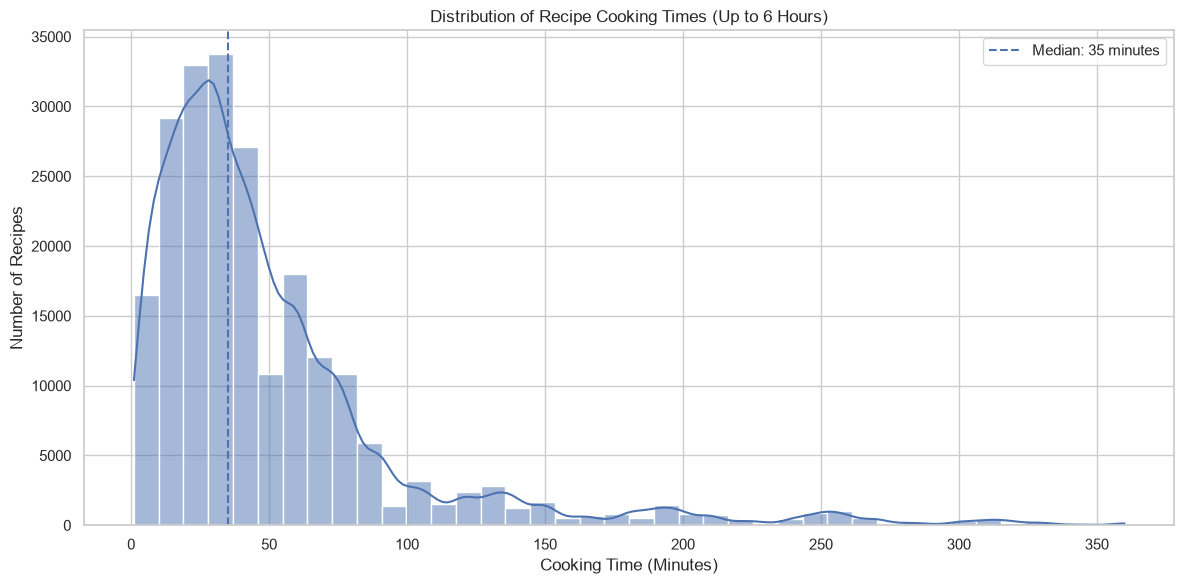

RECIPES INCLUDED IN VISUALIZATION
------------------------------------------------------------
Included recipes: 221813
Total recipes with valid cooking times: 230542
Percentage included: 96.21%
Median cooking time: 35.0 minutes


In [8]:
# Visualize the distribution of typical cooking times

# Select recipes with cooking times up to 6 hours
typical_cooking_times = recipes.loc[
    recipes["minutes"].notna()
    & (recipes["minutes"] <= 360),
    "minutes"
]

# Calculate the number and percentage of included recipes
included_count = len(typical_cooking_times)

total_valid_count = recipes["minutes"].notna().sum()

included_percentage = (
    included_count / total_valid_count
) * 100

# Calculate median cooking time
median_cooking_time = typical_cooking_times.median()

# Create histogram
plt.figure(figsize=(12, 6))

sns.histplot(
    typical_cooking_times,
    bins=40,
    kde=True
)

plt.axvline(
    median_cooking_time,
    linestyle="--",
    label=f"Median: {median_cooking_time:.0f} minutes"
)

plt.title("Distribution of Recipe Cooking Times (Up to 6 Hours)")
plt.xlabel("Cooking Time (Minutes)")
plt.ylabel("Number of Recipes")

plt.legend()
plt.tight_layout()
plt.show()

print("RECIPES INCLUDED IN VISUALIZATION")
print("-" * 60)

print("Included recipes:", included_count)
print("Total recipes with valid cooking times:", total_valid_count)
print(f"Percentage included: {included_percentage:.2f}%")
print("Median cooking time:", median_cooking_time, "minutes")

**Key Findings – Cooking Time Distribution**

- The dataset contains 230,542 recipes with valid cooking-time information.
- A total of 221,813 recipes (96.21%) require six hours or less.
- The median cooking time across all recipes with valid cooking times is 40 minutes.
- The restricted visualization has a median cooking time of 35 minutes.
- Only 3.79% of recipes require more than six hours, indicating that extremely long cooking durations are relatively uncommon.

The cooking-time distribution is right-skewed, with a small number of recipes having exceptionally long durations. Therefore, the median is more representative of a typical recipe than the mean.

### 2.3 Recipe Distribution by Cooking-Time Category

To better understand recipe preparation requirements, recipes are grouped into cooking-time categories.

This analysis provides an overview of how many recipes can be prepared quickly and how many require longer preparation or cooking durations.

RECIPE DISTRIBUTION BY COOKING-TIME CATEGORY
------------------------------------------------------------


,Recipe Count,Percentage
cooking_category,,
Quick,42827,18.58
Short,55131,23.91
Medium,70077,30.40
Long,36683,15.91
Very Long,25824,11.20


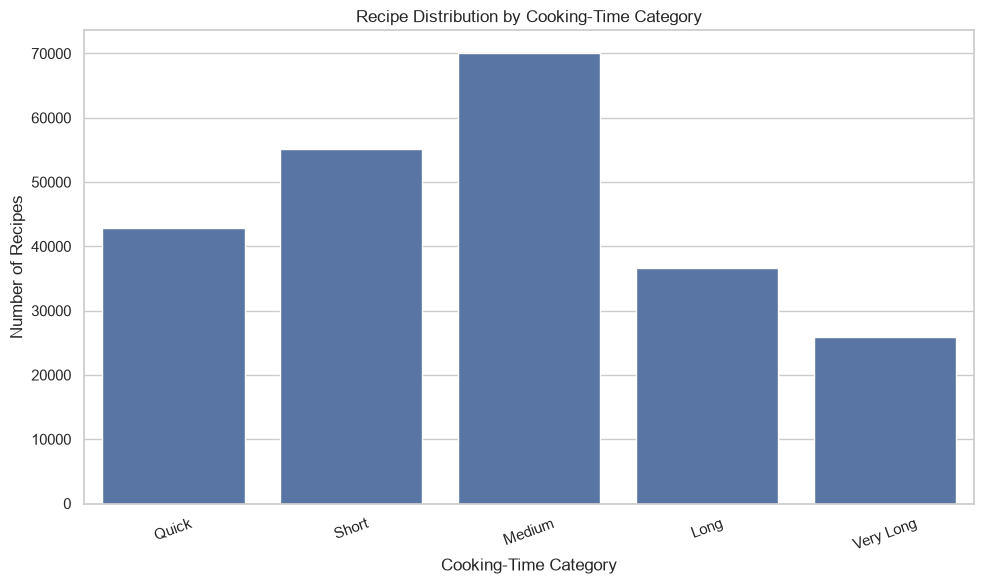

In [9]:
# Create cooking-time categories

cooking_time_data = recipes.loc[
    recipes["minutes"].notna(),
    ["id", "minutes"]
].copy()

cooking_time_data["cooking_category"] = pd.cut(
    cooking_time_data["minutes"],
    bins=[-1, 15, 30, 60, 120, float("inf")],
    labels=[
        "Quick",
        "Short",
        "Medium",
        "Long",
        "Very Long"
    ]
)

# Calculate category counts and percentages

cooking_category_summary = (
    cooking_time_data["cooking_category"]
    .value_counts(sort=False)
    .to_frame(name="Recipe Count")
)

cooking_category_summary["Percentage"] = (
    cooking_category_summary["Recipe Count"]
    / len(cooking_time_data) * 100
).round(2)

print("RECIPE DISTRIBUTION BY COOKING-TIME CATEGORY")
print("-" * 60)

display(cooking_category_summary)

# Visualize category distribution

plt.figure(figsize=(10, 6))

sns.barplot(
    x=cooking_category_summary.index,
    y=cooking_category_summary["Recipe Count"]
)

plt.title("Recipe Distribution by Cooking-Time Category")
plt.xlabel("Cooking-Time Category")
plt.ylabel("Number of Recipes")
plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

### 2.4 Distribution of Recipe Ingredient Counts

This section examines the number of ingredients used in Food.com recipes.

The analysis includes descriptive statistics and a histogram to understand the typical number of ingredients and the variation across recipes.

In [10]:
# Calculate descriptive statistics for ingredient counts

ingredient_summary = recipes["ingredient_count"].describe()

print("RECIPE INGREDIENT COUNT STATISTICS")
print("-" * 60)

display(ingredient_summary.to_frame(name="Ingredient Count"))

RECIPE INGREDIENT COUNT STATISTICS
------------------------------------------------------------


,Ingredient Count
count,231636.000000
mean,9.051149
std,3.734803
min,1.000000
25%,6.000000
50%,9.000000
75%,11.000000
max,43.000000


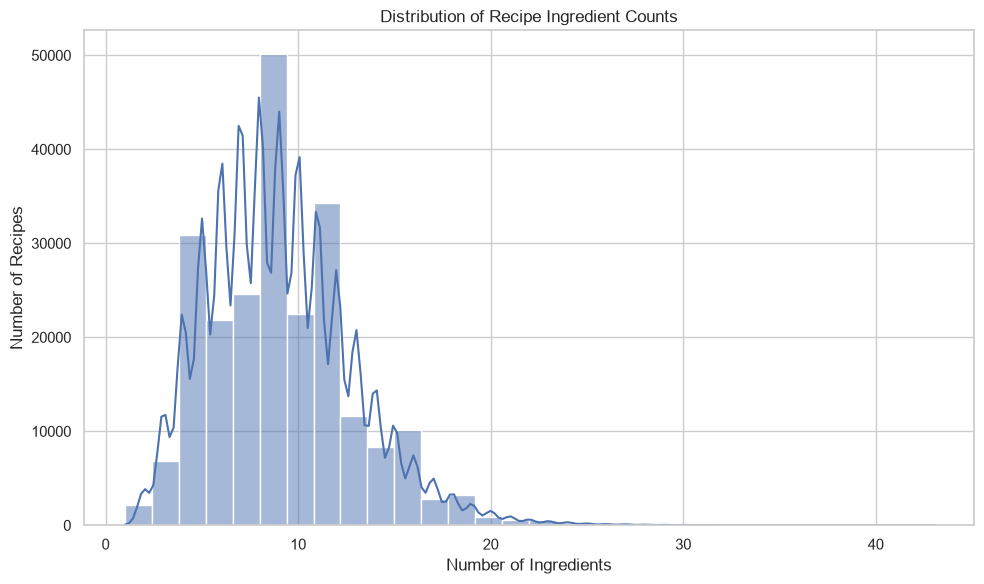

In [11]:
# Visualize the distribution of recipe ingredient counts

plt.figure(figsize=(10, 6))

sns.histplot(
    data=recipes,
    x="ingredient_count",
    bins=30,
    kde=True
)

plt.title("Distribution of Recipe Ingredient Counts")
plt.xlabel("Number of Ingredients")
plt.ylabel("Number of Recipes")

plt.tight_layout()
plt.show()

**Key Findings – Ingredient Count Distribution**

- Most recipes contain approximately 9–10 ingredients.
- The mean (9.05) and median (9) are very close, indicating that the central distribution is relatively balanced.
- 75% of recipes contain 11 or fewer ingredients.
- Recipes containing more than 20 ingredients are relatively uncommon.
- A small number of recipes contain substantially more ingredients, with the maximum reaching 43.

Overall, most Food.com recipes use a moderate number of ingredients, while recipes with very high ingredient counts are less common.

### 2.5 Distribution of Recipe Preparation Steps

This section examines the number of preparation steps required by recipes.

The objective is to understand the typical recipe complexity in terms of instructions and identify recipes with unusually high numbers of steps.

In [12]:
# Calculate descriptive statistics for recipe step counts

step_summary = recipes["step_count"].describe()

print("RECIPE PREPARATION STEP STATISTICS")
print("-" * 60)

display(step_summary.to_frame(name="Step Count"))

RECIPE PREPARATION STEP STATISTICS
------------------------------------------------------------


,Step Count
count,231636.000000
mean,9.765516
std,5.995136
min,0.000000
25%,6.000000
50%,9.000000
75%,12.000000
max,145.000000


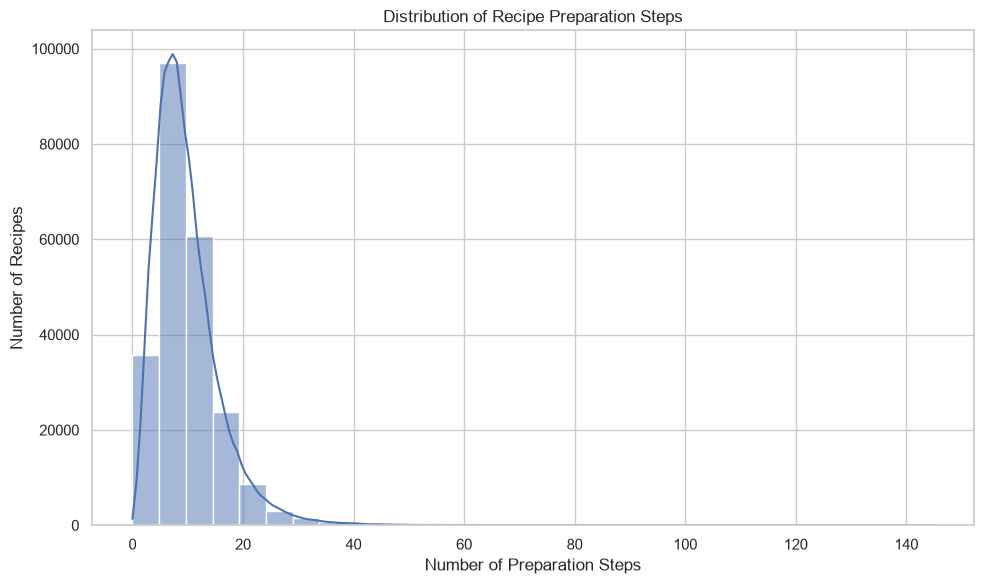

In [13]:
# Visualize the distribution of recipe preparation steps

plt.figure(figsize=(10, 6))

sns.histplot(
    data=recipes,
    x="step_count",
    bins=30,
    kde=True
)

plt.title("Distribution of Recipe Preparation Steps")
plt.xlabel("Number of Preparation Steps")
plt.ylabel("Number of Recipes")

plt.tight_layout()
plt.show()

**Key Findings – Preparation Step Distribution**

- Most recipes contain approximately 9–10 preparation steps.
- The median is 9 steps, while the mean is approximately 9.77 steps.
- The middle 50% of recipes contain between 6 and 12 steps.
- Recipes with more than 40 steps are relatively uncommon.
- The maximum step count is 145, indicating a small number of recipes with unusually detailed instructions.
- A few recipes have zero recorded steps, but these were retained during preprocessing.

Overall, most recipes have a moderate number of preparation steps, while recipes with very lengthy instructions are uncommon.

### 2.6 Distribution of Recipe Tags

This section examines the number of tags associated with each recipe.

Tags provide additional information about recipe characteristics, including cuisine, meal type, dietary preferences, and occasions. Analysing tag counts helps us understand how extensively recipes are categorized in the dataset.

In [14]:
# Calculate descriptive statistics for recipe tag counts

tag_summary = recipes["tag_count"].describe()

print("RECIPE TAG COUNT STATISTICS")
print("-" * 60)

display(tag_summary.to_frame(name="Tag Count"))

RECIPE TAG COUNT STATISTICS
------------------------------------------------------------


,Tag Count
count,231636.000000
mean,17.880101
std,7.244341
min,1.000000
25%,13.000000
50%,17.000000
75%,22.000000
max,73.000000


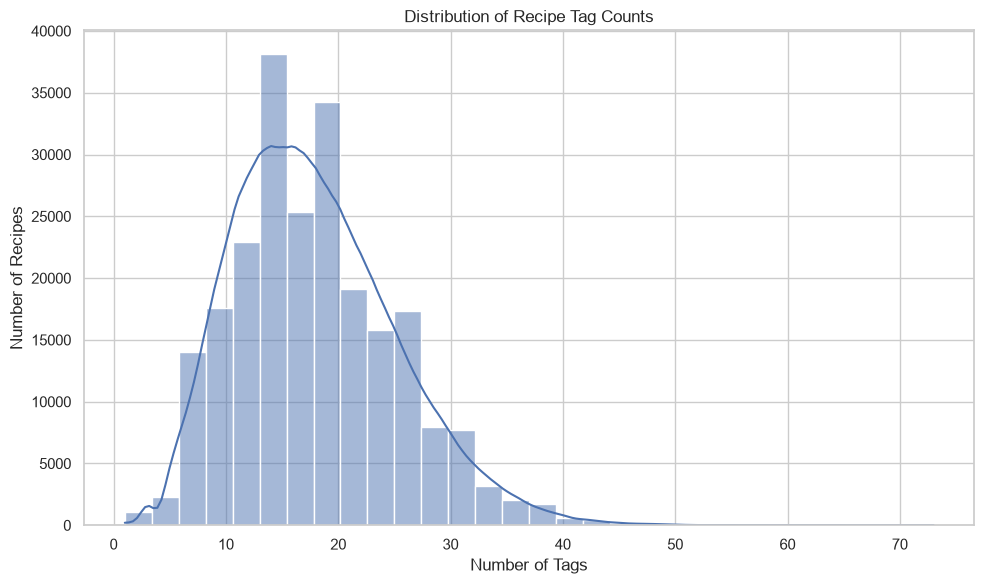

In [15]:
# Visualize the distribution of recipe tag counts

plt.figure(figsize=(10, 6))

sns.histplot(
    data=recipes,
    x="tag_count",
    bins=30,
    kde=True
)

plt.title("Distribution of Recipe Tag Counts")
plt.xlabel("Number of Tags")
plt.ylabel("Number of Recipes")

plt.tight_layout()
plt.show()

**Key Findings – Recipe Tag Distribution**

- Most recipes have between 10 and 20 tags.
- The median tag count is 17, while the mean is approximately 17.88.
- The middle 50% of recipes contain between 13 and 22 tags.
- Recipes with more than 40 tags are relatively uncommon.
- The maximum tag count is 73, indicating that a small number of recipes have extensive categorization.

Overall, most recipes have a moderate number of descriptive tags, while recipes with very high tag counts are less common.

### 2.7 Nutritional Characteristics of Recipes

This section explores the nutritional information available in the Food.com recipe dataset.

We will examine calories and the seven nutritional measurements to understand their distributions, typical values, and potential extreme observations.

The nutritional values are based on the dataset's recorded serving information.

In [18]:
# Calculate descriptive statistics for nutritional columns

nutrition_columns = [
    "calories",
    "total_fat_pdv",
    "sugar_pdv",
    "sodium_pdv",
    "protein_pdv",
    "saturated_fat_pdv",
    "carbohydrates_pdv"
]

nutrition_summary = recipes[nutrition_columns].describe().T

print("RECIPE NUTRITION STATISTICS")
print("-" * 80)

display(nutrition_summary.round(2))

RECIPE NUTRITION STATISTICS
--------------------------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max
calories,231636.0,473.94,1189.71,0.0,174.38,313.4,519.7,434360.2
total_fat_pdv,231636.0,36.08,77.80,0.0,8.00,20.0,41.0,17183.0
sugar_pdv,231636.0,84.30,800.08,0.0,9.00,25.0,68.0,362729.0
sodium_pdv,231636.0,30.15,131.96,0.0,5.00,14.0,33.0,29338.0
protein_pdv,231636.0,34.68,58.47,0.0,7.00,18.0,51.0,6552.0
saturated_fat_pdv,231636.0,45.59,98.24,0.0,7.00,23.0,52.0,10395.0
carbohydrates_pdv,231636.0,15.56,81.82,0.0,4.00,9.0,16.0,36098.0


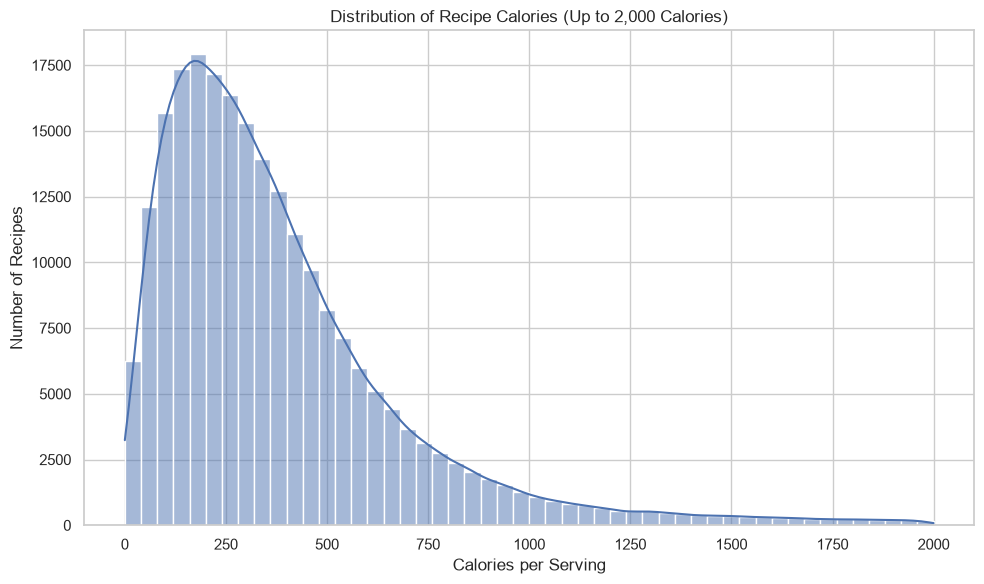

CALORIE VISUALIZATION SUMMARY
------------------------------------------------------------
Total recipes: 231636
Recipes included: 225564
Recipes excluded from visualization: 6072
Percentage included: 97.38 %


In [20]:
# Visualize calorie distribution for recipes up to 2,000 calories

calorie_visualization_data = recipes[
    recipes["calories"] <= 2000
]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=calorie_visualization_data,
    x="calories",
    bins=50,
    kde=True
)

plt.title("Distribution of Recipe Calories (Up to 2,000 Calories)")
plt.xlabel("Calories per Serving")
plt.ylabel("Number of Recipes")

plt.tight_layout()
plt.show()

print("CALORIE VISUALIZATION SUMMARY")
print("-" * 60)
print("Total recipes:", len(recipes))
print("Recipes included:", len(calorie_visualization_data))
print("Recipes excluded from visualization:",
      len(recipes) - len(calorie_visualization_data))
print("Percentage included:",
      round(len(calorie_visualization_data) / len(recipes) * 100, 2), "%")

**Key Findings – Calorie Distribution**

- The original calorie distribution was difficult to interpret because a small number of extreme values stretched the horizontal axis.
- A restricted visualization using recipes with up to 2,000 calories provided a clearer view of the distribution.
- Most recipes appear concentrated around 250–500 calories.
- The frequency of recipes gradually decreases at higher calorie values, particularly beyond approximately 1,000 calories.
- The visualization includes 225,564 recipes (97.38%) and excludes 6,072 recipes (2.62%) from the chart only.
- No observations were removed or modified in the original dataset.

Overall, most recipes have considerably lower calorie values than the extreme observations in the dataset.

PDV VISUALIZATION SUMMARY
---------------------------------------------------------------------------

total_fat_pdv
99th percentile: 302.00
Recipes included: 229322
Recipes excluded: 2314
Percentage included: 99.00%

sugar_pdv
99th percentile: 1141.65
Recipes included: 229319
Recipes excluded: 2317
Percentage included: 99.00%

sodium_pdv
99th percentile: 219.00
Recipes included: 229325
Recipes excluded: 2311
Percentage included: 99.00%

protein_pdv
99th percentile: 188.00
Recipes included: 229341
Recipes excluded: 2295
Percentage included: 99.01%

saturated_fat_pdv
99th percentile: 404.00
Recipes included: 229324
Recipes excluded: 2312
Percentage included: 99.00%

carbohydrates_pdv
99th percentile: 154.00
Recipes included: 229321
Recipes excluded: 2315
Percentage included: 99.00%


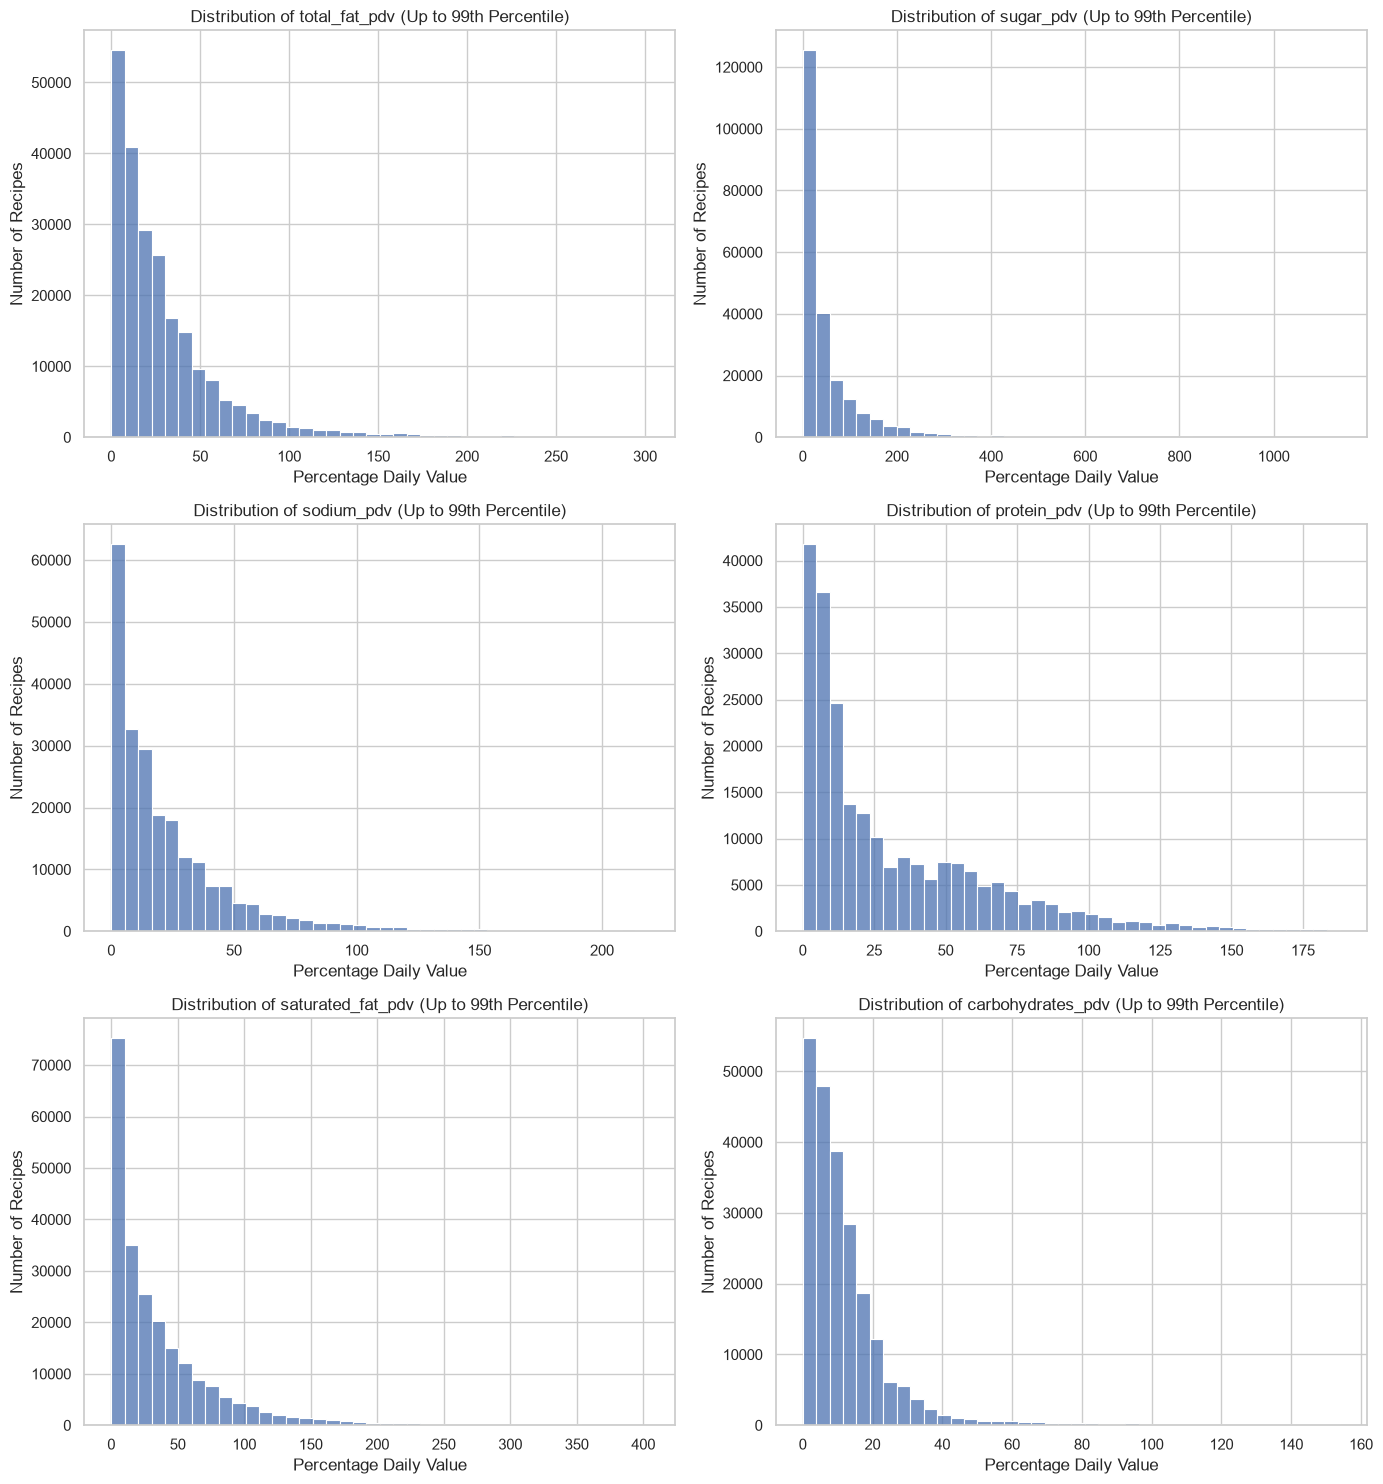

In [22]:
# Visualize nutritional distributions using the 99th percentile

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

print("PDV VISUALIZATION SUMMARY")
print("-" * 75)

for column, ax in zip(pdv_columns, axes.flatten()):

    # Calculate the 99th percentile for this measurement
    upper_limit = recipes[column].quantile(0.99)

    # Restrict data for visualization only
    plot_data = recipes.loc[
        recipes[column] <= upper_limit,
        column
    ]

    # Plot the distribution
    sns.histplot(
        data=plot_data,
        bins=40,
        ax=ax
    )

    ax.set_title(f"Distribution of {column} (Up to 99th Percentile)")
    ax.set_xlabel("Percentage Daily Value")
    ax.set_ylabel("Number of Recipes")

    # Print visualization summary
    excluded_count = len(recipes) - len(plot_data)
    included_percentage = len(plot_data) / len(recipes) * 100

    print(f"\n{column}")
    print(f"99th percentile: {upper_limit:.2f}")
    print(f"Recipes included: {len(plot_data)}")
    print(f"Recipes excluded: {excluded_count}")
    print(f"Percentage included: {included_percentage:.2f}%")

plt.tight_layout()
plt.show()

**Key Findings – Nutritional PDV Distributions**

- The original nutritional histograms were difficult to interpret because extreme values stretched the horizontal axes.
- Individual 99th-percentile thresholds were applied to the six PDV measurements to improve visualization.
- Approximately 99% of recipes were retained in each histogram.
- The restricted histograms provide a clearer view of the distribution of typical nutritional values.
- Each nutritional measurement required a different visualization threshold because their distributions and scales vary.
- Extreme observations were excluded only from the visualizations. No records were removed or modified in the original dataset.

Overall, the nutritional measurements exhibit substantial variation, and using individual percentile-based visualization limits makes their distributions easier to examine.

In [23]:
# Inspect the existing recipe statistics function

from src.ranking import calculate_recipe_statistics

help(calculate_recipe_statistics)

Help on function calculate_recipe_statistics in module src.ranking:

calculate_recipe_statistics(interactions_path, chunksize=100000)
    Calculate valid rating statistics for every recipe.

    Only ratings between 1 and 5 are considered.



## 3. Recipe Ratings and Popularity Analysis

This section explores how users rate Food.com recipes and how popular individual recipes are.

We will calculate recipe-level rating statistics using the reusable ranking module and investigate:

- Number of valid ratings received by each recipe.
- Distribution of average recipe ratings.
- Relationship between rating counts and average ratings.
- Differences between highly rated and highly popular recipes.

Only ratings between 1 and 5 are considered in the rating analysis. Zero ratings are excluded.

In [24]:
# Import the reusable recipe statistics function

from src.ranking import calculate_recipe_statistics

# Calculate rating statistics using the raw interactions dataset

recipe_rating_stats = calculate_recipe_statistics(
    raw_interactions_path
)

print("RECIPE RATING STATISTICS CALCULATED SUCCESSFULLY")

RECIPE RATING STATISTICS CALCULATED SUCCESSFULLY


In [25]:
# Inspect the returned recipe rating statistics

print("RETURNED OBJECT TYPE:")
print(type(recipe_rating_stats))

print("\nDATASET SHAPE:")
print(recipe_rating_stats.shape)

print("\nCOLUMN NAMES:")
print(recipe_rating_stats.columns.tolist())

print("\nFIRST FIVE RECORDS:")
display(recipe_rating_stats.head())

print("\nDESCRIPTIVE STATISTICS:")
display(recipe_rating_stats.describe().T)

RETURNED OBJECT TYPE:
<class 'pandas.DataFrame'>

DATASET SHAPE:
(226590, 6)

COLUMN NAMES:
['rating_count', 'rating_sum', 'rating_squared_sum', 'minimum_rating', 'maximum_rating', 'average_rating']

FIRST FIVE RECORDS:


,rating_count,rating_sum,rating_squared_sum,minimum_rating,maximum_rating,average_rating
recipe_id,,,,,,
38,4,17,73,4,5,4.250000
39,1,3,9,3,3,3.000000
40,9,39,183,1,5,4.333333
41,2,9,41,4,5,4.500000
43,1,1,1,1,1,1.000000



DESCRIPTIVE STATISTICS:


,count,mean,std,min,25%,50%,75%,max
rating_count,226590.0,4.728894,16.582369,1.0,1.000000,2.000000,4.0,1496.0
rating_sum,226590.0,22.043731,78.099068,1.0,5.000000,10.000000,19.0,6866.0
rating_squared_sum,226590.0,105.229114,376.711397,1.0,25.000000,41.000000,91.0,33100.0
minimum_rating,226590.0,4.175184,1.047864,1.0,4.000000,4.000000,5.0,5.0
maximum_rating,226590.0,4.765515,0.590433,1.0,5.000000,5.000000,5.0,5.0
average_rating,226590.0,4.580778,0.629448,1.0,4.333333,4.888889,5.0,5.0


### 2.8.2 Distribution of Recipe Rating Counts

This section examines the number of valid ratings received by individual recipes.

The objective is to understand whether ratings are distributed evenly across recipes or concentrated among a relatively small number of popular recipes.

In [26]:
# Calculate rating-count distribution statistics

rating_count_summary = recipe_rating_stats["rating_count"].describe()

print("RECIPE RATING COUNT STATISTICS")
print("-" * 60)

display(rating_count_summary.to_frame(name="Rating Count"))

RECIPE RATING COUNT STATISTICS
------------------------------------------------------------


,Rating Count
count,226590.000000
mean,4.728894
std,16.582369
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,1496.000000


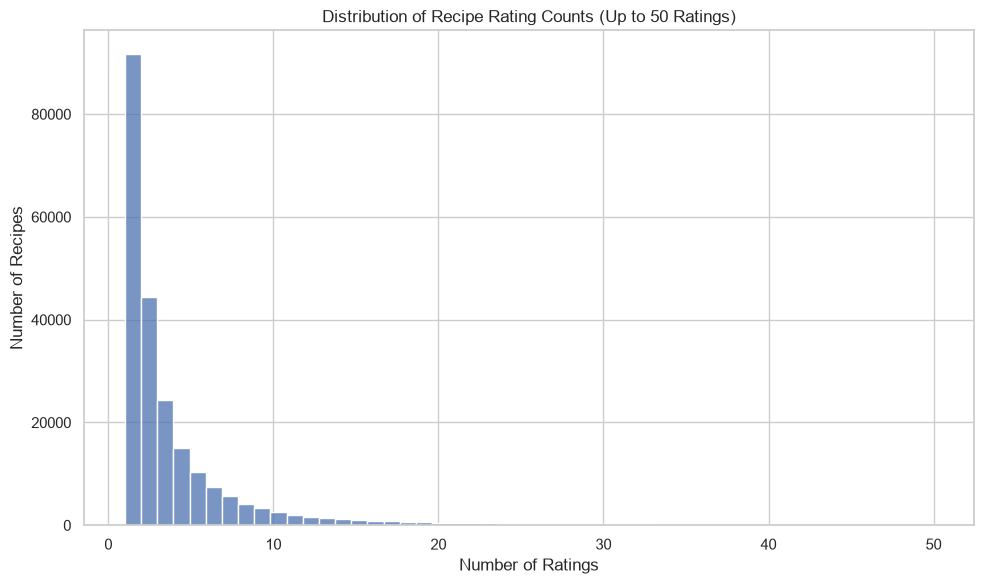

RATING COUNT VISUALIZATION SUMMARY
------------------------------------------------------------
Total recipes: 226590
Recipes included: 224674
Recipes excluded: 1916
Percentage included: 99.15 %


In [27]:
# Visualize the distribution of recipe rating counts

rating_count_visualization = recipe_rating_stats[
    recipe_rating_stats["rating_count"] <= 50
]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=rating_count_visualization,
    x="rating_count",
    bins=50
)

plt.title("Distribution of Recipe Rating Counts (Up to 50 Ratings)")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Recipes")

plt.tight_layout()
plt.show()

print("RATING COUNT VISUALIZATION SUMMARY")
print("-" * 60)

print("Total recipes:", len(recipe_rating_stats))
print("Recipes included:", len(rating_count_visualization))
print(
    "Recipes excluded:",
    len(recipe_rating_stats) - len(rating_count_visualization)
)
print(
    "Percentage included:",
    round(len(rating_count_visualization) / len(recipe_rating_stats) * 100, 2),
    "%"
)

**Key Findings – Recipe Rating Count Distribution**

- Most recipes receive relatively few ratings, with a high concentration in the lower rating-count range.
- The median number of ratings per recipe is only 2.
- 75% of recipes receive four or fewer valid ratings.
- The mean rating count (4.73) is higher than the median (2), indicating a strongly right-skewed distribution.
- A small number of recipes receive hundreds or even over a thousand ratings.

Overall, recipe popularity is highly uneven. Most recipes have limited user feedback, while a relatively small number attract substantially more ratings.

This finding highlights an important limitation of simple average ranking: recipes with very few ratings can achieve perfect average scores without having sufficient user feedback to support their ranking position.

### 2.8.3 Distribution of Average Recipe Ratings

This section examines the average ratings received by individual recipes.

The objective is to understand the overall rating patterns and determine whether recipes generally receive high, moderate, or low average ratings.

In [28]:
# Calculate descriptive statistics for average recipe ratings

average_rating_summary = recipe_rating_stats["average_rating"].describe()

print("AVERAGE RECIPE RATING STATISTICS")
print("-" * 60)

display(average_rating_summary.to_frame(name="Average Rating"))

AVERAGE RECIPE RATING STATISTICS
------------------------------------------------------------


,Average Rating
count,226590.000000
mean,4.580778
std,0.629448
min,1.000000
25%,4.333333
50%,4.888889
75%,5.000000
max,5.000000


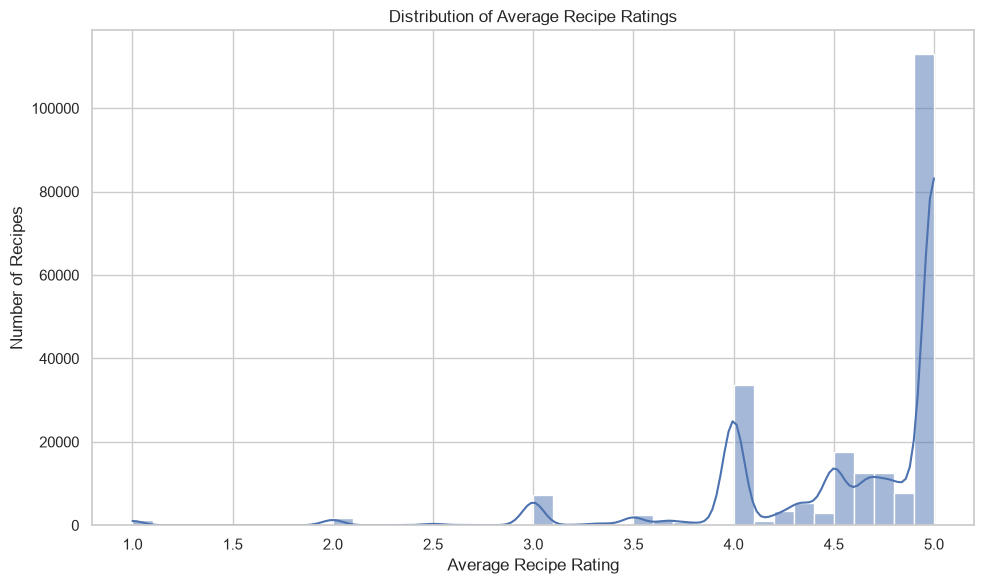

In [29]:
# Visualize the distribution of average recipe ratings

plt.figure(figsize=(10, 6))

sns.histplot(
    data=recipe_rating_stats,
    x="average_rating",
    bins=40,
    kde=True
)

plt.title("Distribution of Average Recipe Ratings")
plt.xlabel("Average Recipe Rating")
plt.ylabel("Number of Recipes")

plt.tight_layout()
plt.show()

**Key Findings – Average Recipe Rating Distribution**

- Most recipes have average ratings concentrated between 4 and 5.
- The mean average rating is approximately 4.58, while the median is 4.89.
- At least 25% of recipes have a perfect average rating of 5.0.
- Recipes with lower average ratings are relatively uncommon.
- The distribution indicates that Food.com recipes generally receive positive user ratings.

An important observation is that high average ratings do not necessarily indicate strong rating support. Many recipes have very few ratings, which can make their average scores less reliable.

This highlights the importance of considering both average ratings and rating counts when developing a recipe-ranking system.

### 2.8.4 Relationship Between Rating Count and Average Rating

This section investigates the relationship between the number of ratings received by a recipe and its average rating.

The objective is to understand how rating volume relates to recipe scores and whether recipes with fewer ratings show greater variation in their average ratings.

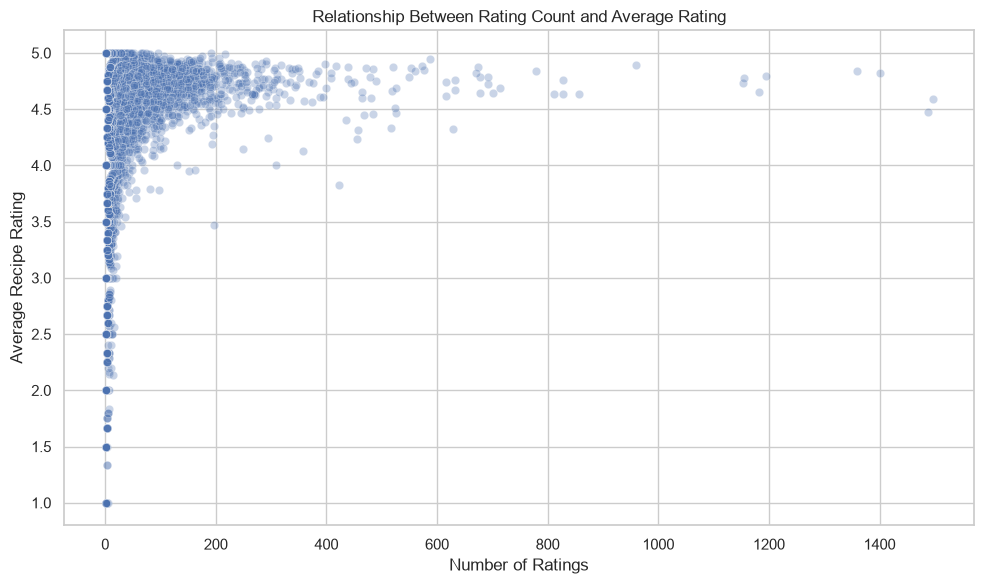

In [31]:
# Visualize the relationship between rating count and average rating

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=recipe_rating_stats,
    x="rating_count",
    y="average_rating",
    alpha=0.3
)

plt.title("Relationship Between Rating Count and Average Rating")
plt.xlabel("Number of Ratings")
plt.ylabel("Average Recipe Rating")

plt.tight_layout()
plt.show()

**Key Findings – Relationship Between Rating Count and Average Rating**

- A large concentration of recipes appears near an average rating of 5, particularly among recipes with relatively few ratings.
- Most recipes receive fewer than 200 ratings.
- Recipes with more than 200 ratings are relatively uncommon.
- Many recipes achieve high average ratings despite having limited user feedback.
- The scatter plot highlights the importance of considering rating count alongside average rating when evaluating recipe quality.

Overall, average ratings alone may not provide sufficient evidence of a recipe's reliability. Rating volume is another important factor to consider in the ranking process.

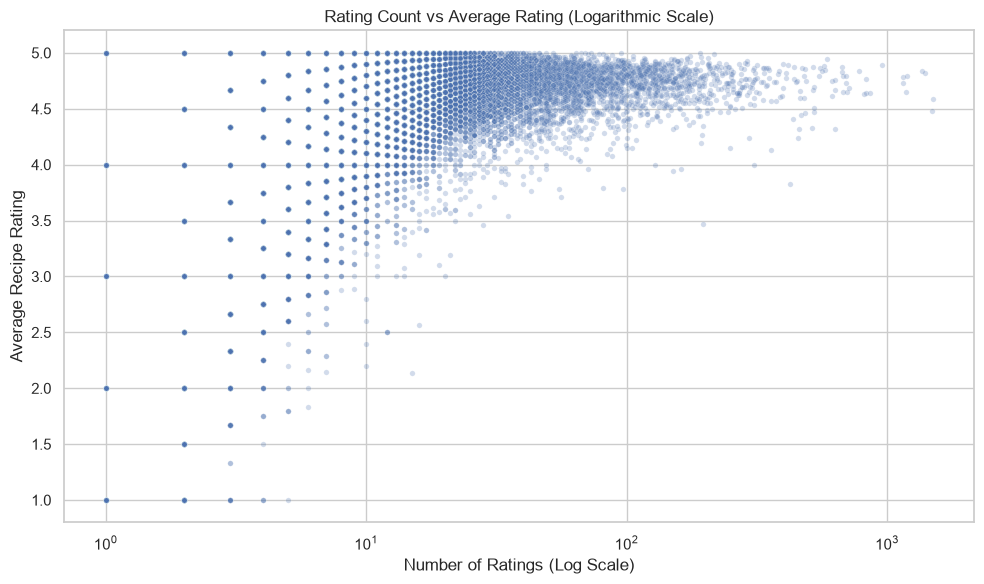

In [32]:
# Visualize rating count and average rating using a logarithmic scale

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=recipe_rating_stats,
    x="rating_count",
    y="average_rating",
    alpha=0.25,
    s=15
)

plt.xscale("log")

plt.title("Rating Count vs Average Rating (Logarithmic Scale)")
plt.xlabel("Number of Ratings (Log Scale)")
plt.ylabel("Average Recipe Rating")

plt.tight_layout()
plt.show()

**Key Findings:**

The logarithmic scale provides a clearer view of the relationship between rating count and average rating.

- A larger concentration of recipes is observed in the range of 10–100 ratings.
- The number of recipes decreases considerably in the range of 100–1,000 ratings, although individual observations remain visible.
- Very few recipes receive more than 1,000 ratings.
- The plot also helps examine how average ratings vary across recipes with different levels of rating activity.

This indicates that rating activity is highly uneven across recipes. Therefore, considering the number of ratings alongside the average rating is important when developing a reliable recipe-ranking system.

### 3.4 Correlation Between Rating Count and Average Rating

This section investigates whether the number of ratings received by a recipe is associated with its average rating.

Two correlation methods are used:

- **Pearson correlation:** Measures the strength and direction of a linear relationship.
- **Spearman correlation:** Measures the strength and direction of a monotonic relationship using ranked values.

Using both methods helps us understand the relationship from different perspectives.

In [38]:
# Calculate rating correlations using the reusable function
correlation_results = ranking.calculate_rating_correlations(
    recipe_rating_stats
)

# Display results
print("CORRELATION ANALYSIS")
print("-" * 55)
print(correlation_results)

CORRELATION ANALYSIS
-------------------------------------------------------
number_of_recipes       226590.000000
pearson_correlation          0.036571
spearman_correlation        -0.112213
dtype: float64


**Key Findings:**

- The Pearson correlation coefficient is approximately +0.0366, indicating an extremely weak positive linear relationship between rating count and average rating.
- The Spearman correlation coefficient is approximately -0.1122, indicating a weak negative monotonic relationship.
- Both coefficients are close to zero, suggesting that rating count and average rating have very little overall association.
- The weak negative Spearman correlation suggests that recipes receiving more ratings tend to have slightly lower average ratings in ranked terms.

These results indicate that the number of ratings alone does not strongly determine a recipe's average rating. Therefore, considering both rating volume and average rating is important when evaluating recipes for ranking.

### 3.5 Average Ratings Across Different Rating-Count Groups

To further investigate the relationship between rating count and average rating, recipes are divided into groups based on the number of valid ratings they received.

This analysis compares the mean and median average ratings across groups to understand whether recipes with different levels of rating activity show different rating patterns.

In [39]:
# Create a copy of recipe statistics
grouped_rating_data = recipe_rating_stats.copy()

# Define rating-count categories
bins = [0, 5, 10, 50, 100, float("inf")]

labels = [
    "1–5",
    "6–10",
    "11–50",
    "51–100",
    "101+"
]

# Assign each recipe to a rating-count group
grouped_rating_data["rating_count_group"] = pd.cut(
    grouped_rating_data["rating_count"],
    bins=bins,
    labels=labels
)

# Calculate summary statistics for each group
rating_group_summary = (
    grouped_rating_data
    .groupby("rating_count_group", observed=True)
    .agg(
        recipe_count=("average_rating", "count"),
        mean_average_rating=("average_rating", "mean"),
        median_average_rating=("average_rating", "median"),
        minimum_average_rating=("average_rating", "min"),
        maximum_average_rating=("average_rating", "max")
    )
)

# Calculate percentage of recipes in each group
rating_group_summary["percentage"] = (
    rating_group_summary["recipe_count"] /
    len(grouped_rating_data) * 100
)

# Display results
print("AVERAGE RATINGS BY RATING-COUNT GROUP")
print("-" * 75)

display(rating_group_summary.round(3))

AVERAGE RATINGS BY RATING-COUNT GROUP
---------------------------------------------------------------------------


,recipe_count,mean_average_rating,median_average_rating,minimum_average_rating,maximum_average_rating,percentage
rating_count_group,,,,,,
1–5,185993,4.557,5.000,1.000,5.0,82.083
6–10,23045,4.684,4.778,1.833,5.0,10.170
11–50,15636,4.701,4.750,2.133,5.0,6.901
51–100,1216,4.707,4.742,3.714,5.0,0.537
101+,700,4.714,4.741,3.469,5.0,0.309


**Key Findings:**

- A large majority of recipes (82.08%) have only 1–5 valid ratings, indicating that rating activity is highly concentrated among recipes with limited feedback.
- The mean average rating gradually increases from 4.557 in the 1–5 rating group to 4.714 in the 101+ rating group.
- The median average rating is 5.000 for recipes with only 1–5 ratings, while it ranges between approximately 4.74 and 4.78 for recipes with more than five ratings.
- This indicates that recipes with fewer ratings frequently achieve perfect average scores, but these scores are based on limited feedback.
- Recipes with larger rating counts show a narrower range of average ratings compared with recipes having fewer ratings.

Overall, the analysis highlights the importance of considering rating volume alongside average rating when evaluating recipe quality.

## 4. Exploratory Data Analysis – Overall Conclusion

The exploratory data analysis provided an understanding of recipe characteristics, cooking times, nutritional information, and user rating behaviour in the Food.com dataset.

The main findings are:

1. **Recipe characteristics:** Most recipes contain approximately 9 ingredients, 9–10 preparation steps, and 10–20 tags.

2. **Cooking time:** The cooking-time distribution is right-skewed. The median cooking time is 40 minutes, indicating that most recipes have relatively short preparation times, although some recipes contain unusually large cooking-time values.

3. **Nutrition:** Nutritional variables show right-skewed distributions with extreme observations. Median values provide a more representative description of typical recipes.

4. **Rating distribution:** Most individual user ratings are 4 or 5, and the overall average rating is approximately 4.66.

5. **Rating volume:** The median number of valid ratings per recipe is only 2, and approximately 82% of recipes have between 1 and 5 ratings.

6. **Correlation analysis:** Pearson correlation (0.0366) and Spearman correlation (-0.1122) indicate very weak relationships between rating count and average rating.

7. **Rating-count group analysis:** Recipes with fewer ratings frequently have perfect average scores, highlighting the limitations of relying only on simple average ratings.

### Implications for the Recipe Ranking System

The EDA highlights an important challenge: recipes with very few ratings can achieve perfect average scores, making them difficult to compare fairly with recipes supported by substantially more user feedback.

Therefore, the project will compare simple average ranking with weighted average and Bayesian ranking approaches to investigate how incorporating rating volume and a prior rating can produce more balanced rankings.